# 01 · Dataset exploration

Dataset **v1** built by `python -m ml.src.prepare_data`. Sources, licences, cleaning statistics and class distribution all come from `ml/reports/dataset_report.json` and the manifest — nothing in this notebook is typed in by hand.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / 'ml' / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
DATA_DIR = os.environ.get('WASTEWISE_DATA_DIR', str(ROOT / 'ml/datasets/processed'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160)

In [2]:
rep = json.load(open('ml/reports/dataset_report.json'))
pd.DataFrame(rep['sources']).T[['name', 'license', 'url']]

,name,license,url
trashnet,"TrashNet (Thung & Yang, 2016)",MIT,https://github.com/garythung/trashnet
garbage12,"Garbage Classification (12 classes), Mostafa M...",ODbL 1.0 (database); image contents (c) origin...,https://www.kaggle.com/datasets/mostafaabla/ga...
household30,"Recyclable and Household Waste Classification,...",MIT (Kaggle listing); dataset card: educationa...,https://www.kaggle.com/datasets/alistairking/r...
ewastenet,"E-Waste Vision Dataset (EWasteNet, Islam et al.)",No explicit license in repository — academic u...,https://github.com/NifulIslam/EWasteNet-A-Two-...


## Cleaning summary

In [3]:
keys = ['raw_total_in_taxonomy', 'exact_duplicates_removed', 'exact_duplicate_label_conflicts_dropped',
        'near_duplicate_groups', 'near_duplicate_cross_dataset_groups', 'near_duplicate_images_collapsed',
        'near_duplicate_label_conflicts_dropped', 'imbalance_ratio_max_min']
pd.Series({k: rep[k] for k in keys})

raw_total_in_taxonomy                      24284.000000
exact_duplicates_removed                    6014.000000
exact_duplicate_label_conflicts_dropped       82.000000
near_duplicate_groups                       1300.000000
near_duplicate_cross_dataset_groups           15.000000
near_duplicate_images_collapsed             1687.000000
near_duplicate_label_conflicts_dropped        59.000000
imbalance_ratio_max_min                        3.859649
dtype: float64

## Class distribution per split

split,train,validation,test
category,,,
e_waste,771,162,167
glass,767,165,168
hazardous,199,43,43
metal,772,163,165
organic,770,165,165
paper_cardboard,763,169,168
plastic,762,170,168


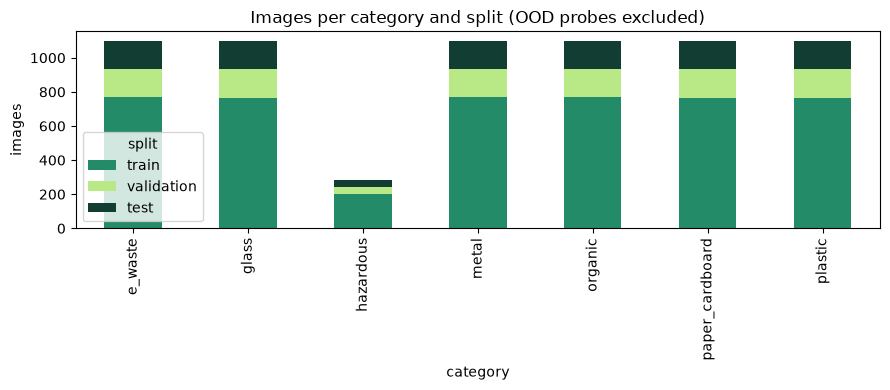

In [4]:
m = pd.read_csv('ml/datasets/manifests/manifest_v1.csv', dtype={'uid': str})
lab = m[m.split != 'ood']
tab = pd.crosstab(lab['category'], lab['split'])[['train', 'validation', 'test']]
display(tab)
ax = tab.plot.bar(stacked=True, figsize=(9, 4), color=['#238B67', '#B8E986', '#123D32'])
ax.set_ylabel('images'); ax.set_title('Images per category and split (OOD probes excluded)'); plt.tight_layout()

## Source dataset per category (domain mix)

In [5]:
display(pd.crosstab(lab['category'], lab['dataset']))
print('OOD probe images (never trained on):'); m[m.split == 'ood']['stratum'].value_counts()

dataset,ewastenet,garbage12,household30,trashnet
category,,,,
e_waste,841,259,0,0
glass,0,362,618,120
hazardous,0,0,285,0
metal,0,161,778,161
organic,0,145,955,0
paper_cardboard,0,158,786,156
plastic,0,46,1009,45


OOD probe images (never trained on):


stratum
garbage12_mirror/extra/large_garb_dataset/clothes    60
garbage12_mirror/extra/large_garb_dataset/shoes      60
garbage12_mirror/extra/large_garb_dataset/trash      60
household30/images/clothing/default                  60
household30/images/clothing/real_world               60
household30/images/paper_cups/default                60
household30/images/paper_cups/real_world             60
household30/images/shoes/default                     60
household30/images/shoes/real_world                  60
trashnet/data/dataset-resized/trash                  60
Name: count, dtype: int64

## Leakage check — no near-duplicate group may span two splits

In [6]:
g = m[m.split != 'ood'].groupby('group')['split'].nunique()
print('groups spanning >1 split:', int((g > 1).sum()))
print('duplicate md5 across manifest:', int(m['md5'].duplicated().sum()))

groups spanning >1 split: 0
duplicate md5 across manifest: 0


## Sample images

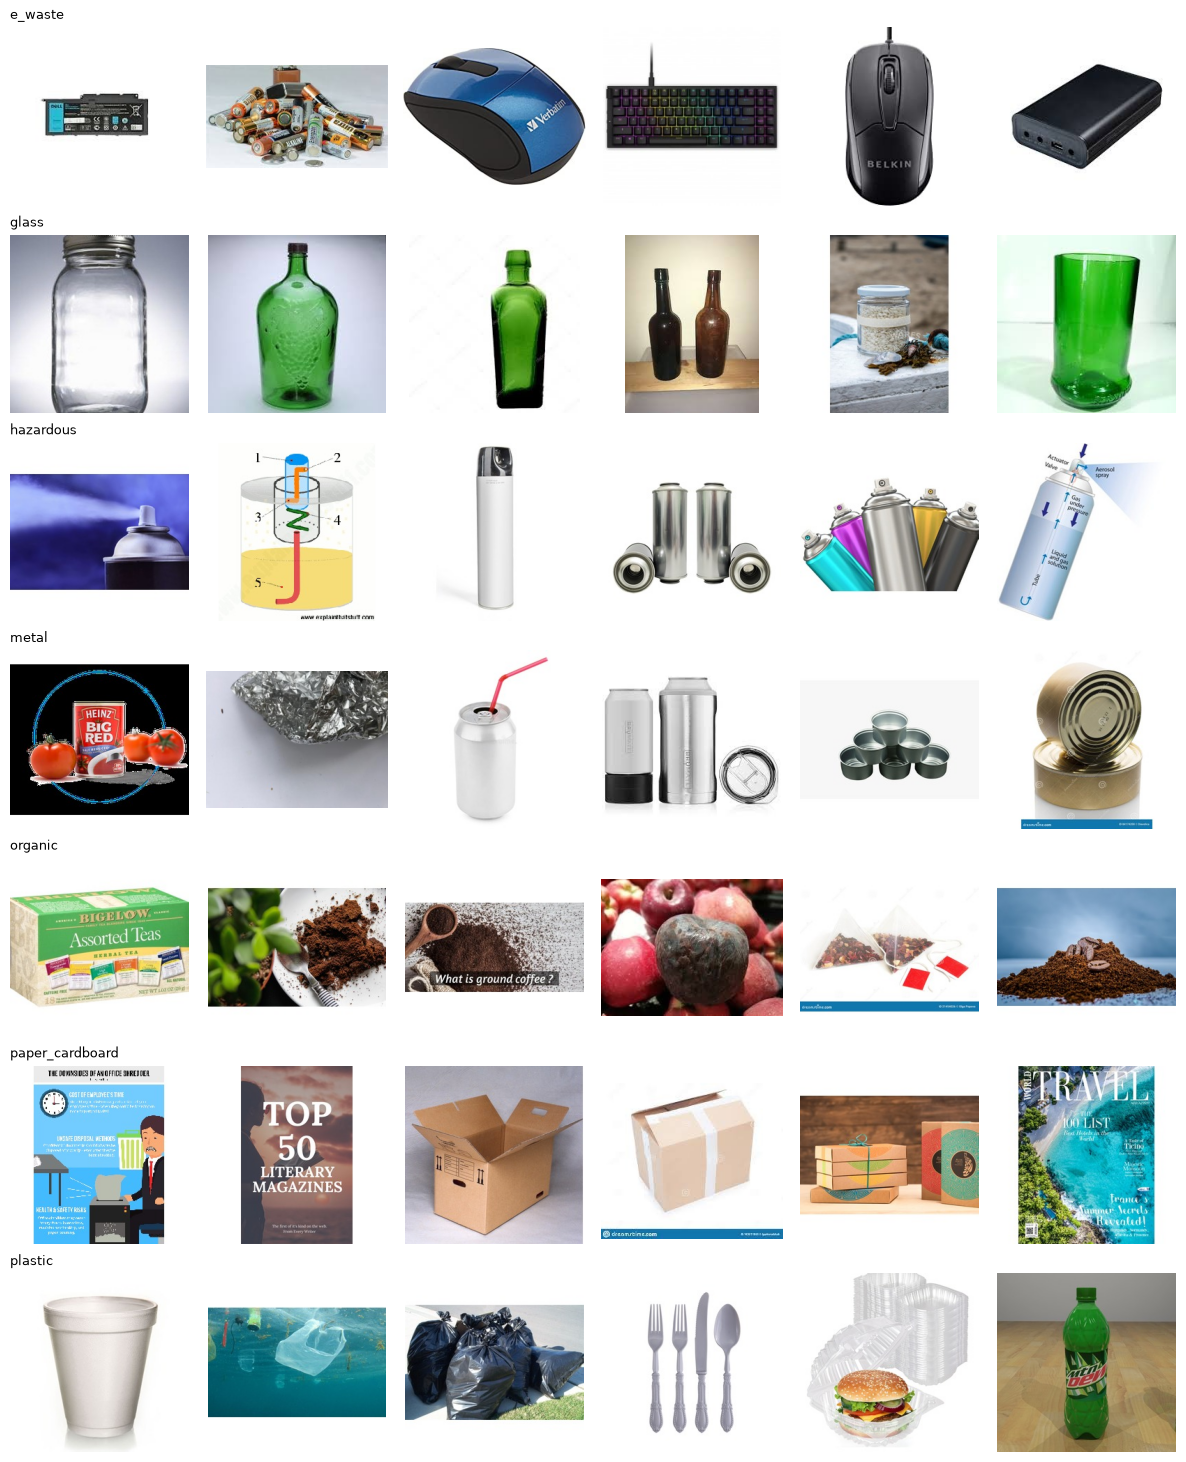

In [7]:
from PIL import Image
cats = list(m['category'].dropna().unique())
fig, axes = plt.subplots(len(cats), 6, figsize=(12, 2.1 * len(cats)))
for r, c in enumerate(sorted(cats)):
    s = m[(m.category == c) & (m.split == 'train')].sample(6, random_state=0)
    for k, (_, row) in enumerate(s.iterrows()):
        ax = axes[r, k]; ax.imshow(Image.open(os.path.join(DATA_DIR, row['file']))); ax.axis('off')
        if k == 0: ax.set_title(c, loc='left', fontsize=9)
plt.tight_layout()

## Source image sizes (as found in the raw datasets, before resizing to short side 256)

In [8]:
m[['width', 'height']].describe()

,width,height
count,7485.000000,7485.000000
mean,280.290581,261.285504
std,84.623132,57.644477
min,51.000000,94.000000
25%,256.000000,256.000000
50%,256.000000,256.000000
75%,256.000000,256.000000
max,1600.000000,900.000000


### Known limitations
- **Hazardous** = aerosol cans only (285 unique images); no public hazardous-waste dataset was found. Class weights compensate for imbalance but cannot add missing visual variety.
- household30 is licensed for *educational / research / non-commercial* use; EWasteNet has no explicit licence (academic use with citation). The trained model inherits these restrictions.